# Weather task previews: MTBench vs NOAA

Random samples for each weather task, from the original MTBench folders and the new NOAA folders.
Change `N` or `SEED` to see a different subset.

In [43]:
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.append("..")
from evaluation.utils import compute_temperature_trend, get_temperature_diff_max_min
from evaluation.weather.meta_prompt import weather_mcqa_metaprompt_generation

DATA = Path("../data/processed/weather")
N = 3
SEED = 0

# setting -> (MTBench folder, NOAA folder) for the aligned (time series) tasks and for MCQA
ALIGNED = {
    "7-day in, 1-day out": (
        "aligned_in7days_out1days",
        "noaa_aligned_in7days_out1days",
    ),
    "14-day in, 3-day out": (
        "aligned_in14days_out3days",
        "noaa_aligned_in14days_out3days",
    ),
}
MCQA = {
    "short (7 days)": ("QAshort", "noaa_QAshort"),
    "long (14 days)": ("QAlong", "noaa_QAlong"),
}


def sample_files(folder, n=N, seed=SEED):
    files = sorted((DATA / folder).glob("*.json"))
    return random.Random(seed).sample(files, n)


def load(path):
    with open(path) as f:
        return json.load(f)


def short(text, n=400):
    return text if len(text) <= n else text[:n] + " ..."

## Time series tasks

Temperature forecasting, trend classification and indicator prediction all read the same aligned files
(`text`, `input_window`, `output_window`), so one plot per sample is shown with each task's label underneath.

In [44]:
def preview_aligned(task_note, label_fn):
    for setting, folders in ALIGNED.items():
        for source, folder in zip(["MTBench", "NOAA"], folders):
            print(f"{'=' * 100}\n{task_note} | {setting} | {source} ({folder})")
            files = sample_files(folder)
            fig, axes = plt.subplots(
                1, len(files), figsize=(5 * len(files), 3), squeeze=False
            )
            for ax, path in zip(axes[0], files):
                d = load(path)
                n_in = len(d["input_window"])
                ax.plot(range(n_in), d["input_window"], label="input")
                ax.plot(
                    range(n_in, n_in + len(d["output_window"])),
                    d["output_window"],
                    label="output",
                )
                ax.set_title(path.stem, fontsize=8)
                ax.legend(fontsize=7)
            plt.tight_layout()
            plt.show()
            for path in files:
                d = load(path)
                print(f"[{path.name}] {label_fn(d)}")
                print("   report:", short(d["text"]))

### Temperature forecasting

Temperature forecasting | 7-day in, 1-day out | MTBench (aligned_in7days_out1days)


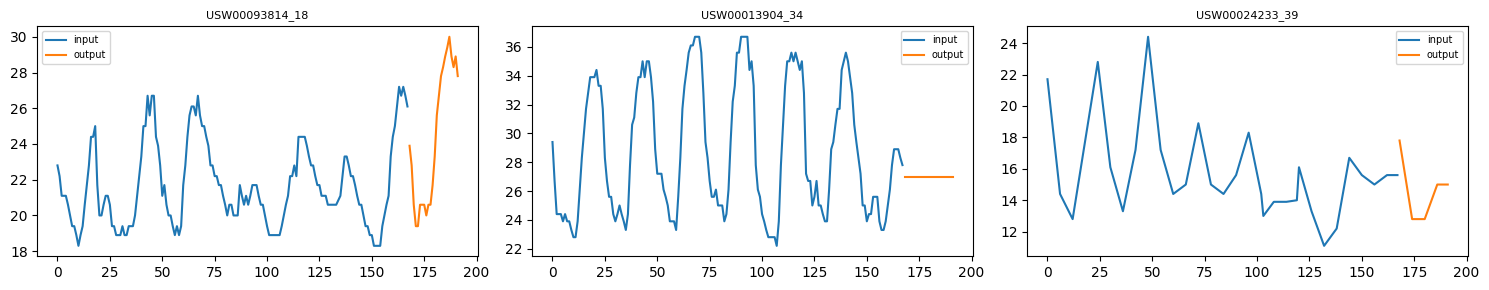

[USW00093814_18.json] input 168 h -> predict 24 h
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] input 168 h -> predict 24 h
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] input 168 h -> predict 24 h
   report: The fol

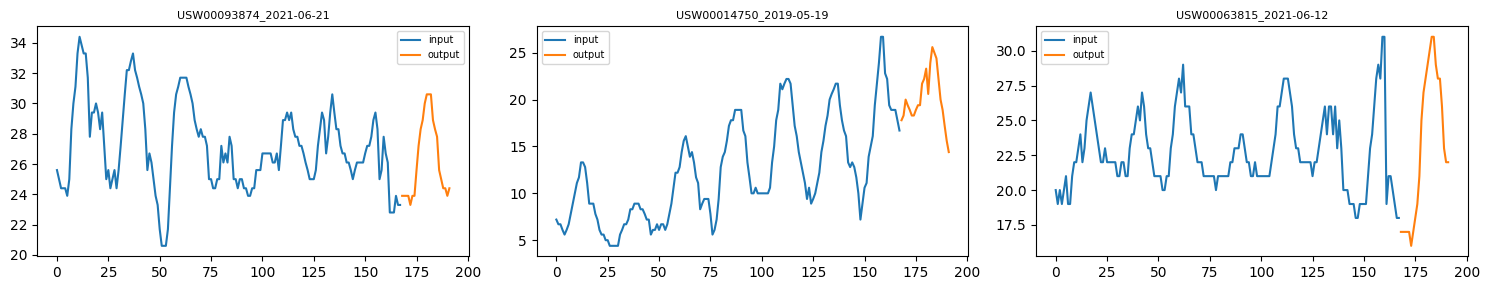

[USW00093874_2021-06-21.json] input 168 h -> predict 24 h
   report: The following events were reported: Flash Flood. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 5.3 to 15.3 km away, between 2021-06-21 19:30 and 2021-06-21 21:00 local standard time. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Injuries: 0; deaths: 0. Episode Narrative: An upper level trough brought a cold front to the region. Ahead of this cold front ...
[USW00014750_2019-05-19.json] input 168 h -> predict 24 h
   report: The following events were reported: Flood, Hail, Thunderstorm Wind. They occurred near station USW00014750 (SARATOGA,NEW YORK), 3.4 to 21.0 km away, between 2019-05-19 16:43 and 2019-05-19 19:55 local standard time. Hail: 1.00 inch hail. Thunderstorm Wind: estimated 50.00 knot wind gust. Thunderstorm Wind: estimated 60.00 knot wind gust. Hail: 1.00 inch hail. Thunderstorm Wind: estimated 50.00 kno ...
[USW00063815_2021-06-12.json] input 168 h -> predict

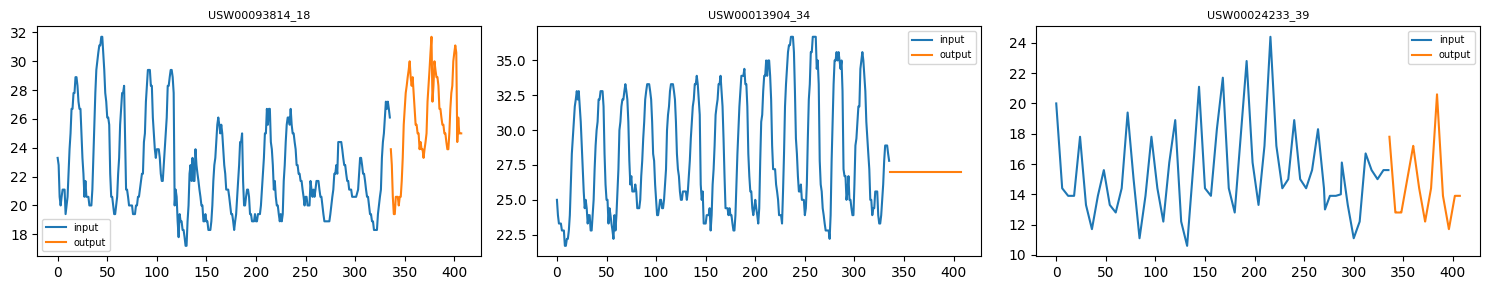

[USW00093814_18.json] input 336 h -> predict 72 h
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] input 336 h -> predict 72 h
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] input 336 h -> predict 72 h
   report: The fol

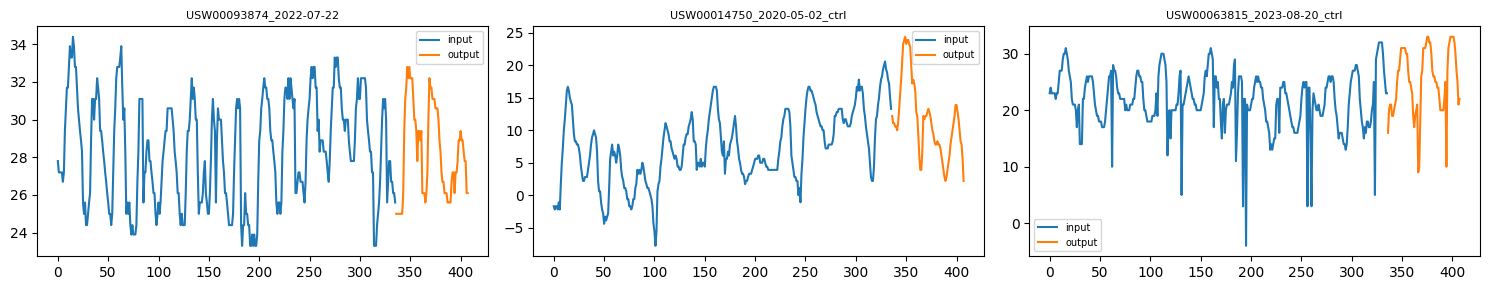

[USW00093874_2022-07-22.json] input 336 h -> predict 72 h
   report: The following events were reported: Marine Thunderstorm Wind. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 6.2 to 6.4 km away, between 2022-07-22 01:10 and 2022-07-22 01:47 local standard time. Marine Thunderstorm Wind: measured 43.00 knot wind gust. Marine Thunderstorm Wind: measured 36.00 knot wind gust. Injuries: 0; deaths: 0. Episode Narrative: A meso-scale convective system  ...
[USW00014750_2020-05-02_ctrl.json] input 336 h -> predict 72 h
   report: No severe weather events were reported within 50 km of station USW00014750 (SARATOGA,NEW YORK) on 2020-05-02.
[USW00063815_2023-08-20_ctrl.json] input 336 h -> predict 72 h
   report: No severe weather events were reported within 50 km of station USW00063815 (PULASKI,KENTUCKY) on 2023-08-20.


In [45]:
preview_aligned(
    "Temperature forecasting",
    lambda d: f"input {len(d['input_window'])} h -> predict {len(d['output_window'])} h",
)

### Trend classification

Trend classification | 7-day in, 1-day out | MTBench (aligned_in7days_out1days)


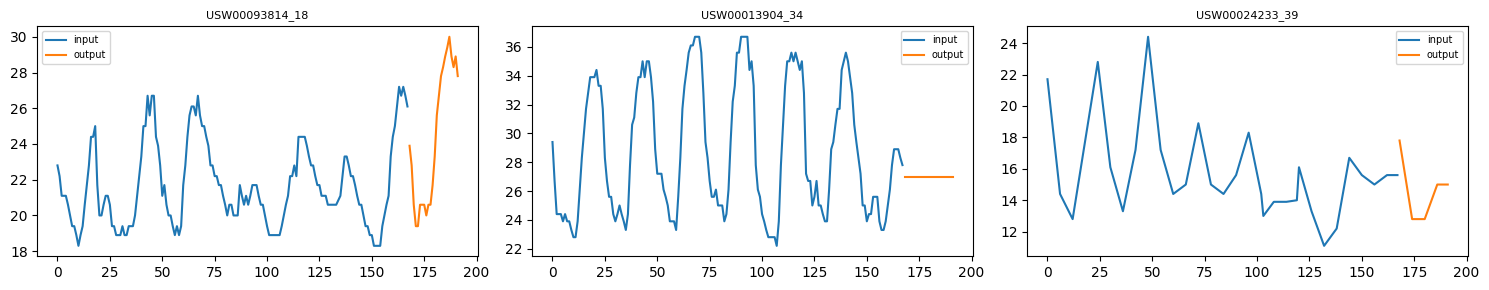

[USW00093814_18.json] past trend: stable, future trend: increasing
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] past trend: stable, future trend: increasing
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] past trend: 

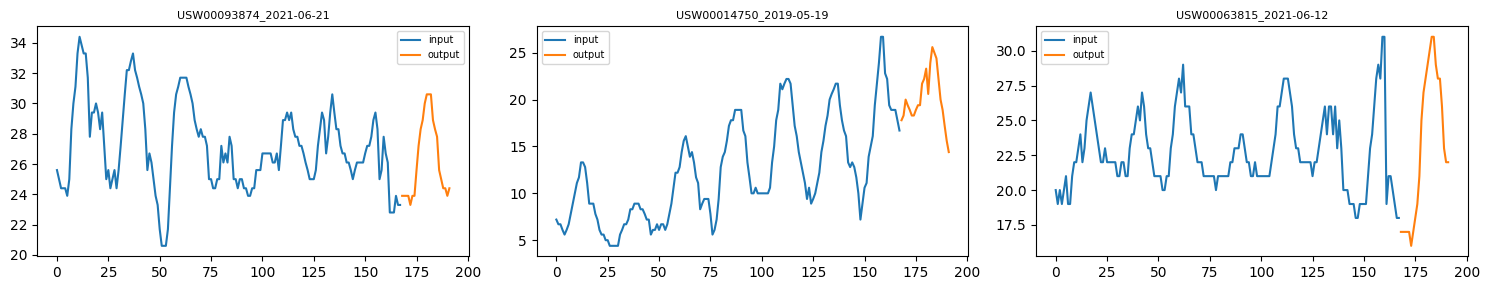

[USW00093874_2021-06-21.json] past trend: decreasing, future trend: stable
   report: The following events were reported: Flash Flood. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 5.3 to 15.3 km away, between 2021-06-21 19:30 and 2021-06-21 21:00 local standard time. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Injuries: 0; deaths: 0. Episode Narrative: An upper level trough brought a cold front to the region. Ahead of this cold front ...
[USW00014750_2019-05-19.json] past trend: increasing, future trend: increasing
   report: The following events were reported: Flood, Hail, Thunderstorm Wind. They occurred near station USW00014750 (SARATOGA,NEW YORK), 3.4 to 21.0 km away, between 2019-05-19 16:43 and 2019-05-19 19:55 local standard time. Hail: 1.00 inch hail. Thunderstorm Wind: estimated 50.00 knot wind gust. Thunderstorm Wind: estimated 60.00 knot wind gust. Hail: 1.00 inch hail. Thunderstorm Wind: estimated 50.00 kno ...
[USW00063815_2

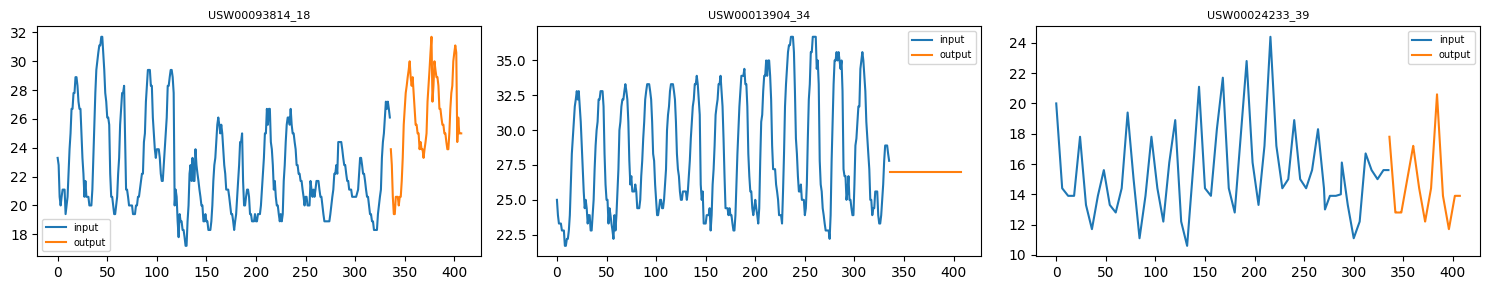

[USW00093814_18.json] past trend: stable, future trend: increasing
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] past trend: stable, future trend: increasing
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] past trend: 

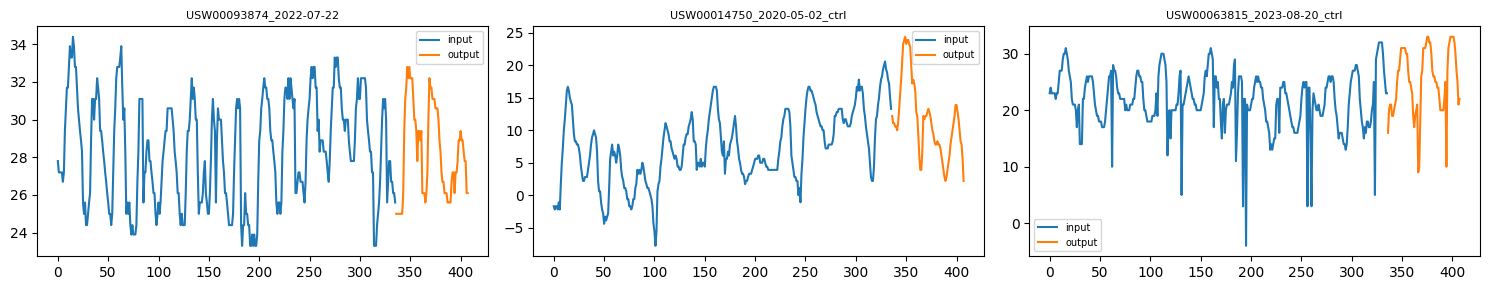

[USW00093874_2022-07-22.json] past trend: stable, future trend: increasing
   report: The following events were reported: Marine Thunderstorm Wind. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 6.2 to 6.4 km away, between 2022-07-22 01:10 and 2022-07-22 01:47 local standard time. Marine Thunderstorm Wind: measured 43.00 knot wind gust. Marine Thunderstorm Wind: measured 36.00 knot wind gust. Injuries: 0; deaths: 0. Episode Narrative: A meso-scale convective system  ...
[USW00014750_2020-05-02_ctrl.json] past trend: increasing, future trend: decreasing
   report: No severe weather events were reported within 50 km of station USW00014750 (SARATOGA,NEW YORK) on 2020-05-02.
[USW00063815_2023-08-20_ctrl.json] past trend: stable, future trend: increasing
   report: No severe weather events were reported within 50 km of station USW00063815 (PULASKI,KENTUCKY) on 2023-08-20.


In [46]:
preview_aligned(
    "Trend classification",
    lambda d: (
        f"past trend: {compute_temperature_trend(d['input_window'])}, "
        f"future trend: {compute_temperature_trend(d['input_window'], d['output_window'])}"
    ),
)

### Indicator prediction (first output day)

Indicator prediction | 7-day in, 1-day out | MTBench (aligned_in7days_out1days)


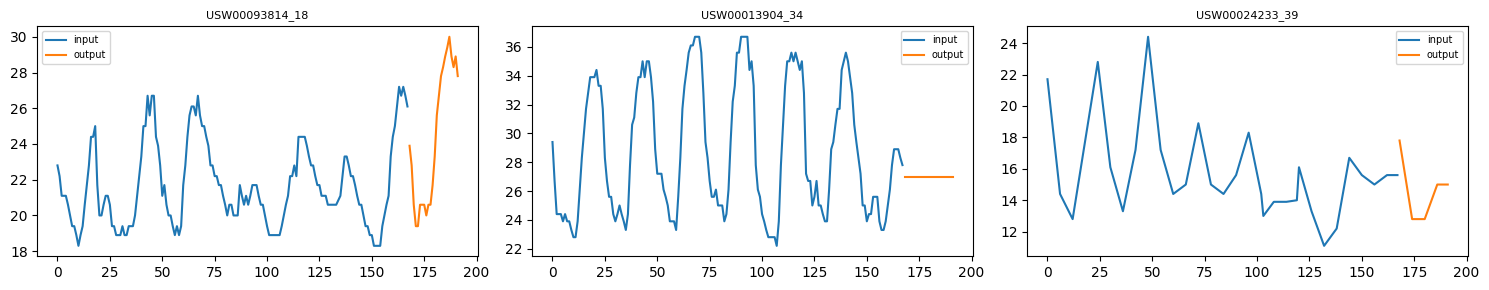

[USW00093814_18.json] {'max': 30.0, 'min': 19.4, 'diff': 10.6}
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] {'max': 27.0, 'min': 27.0, 'diff': 0.0}
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] {'max': 17.8, 'min': 

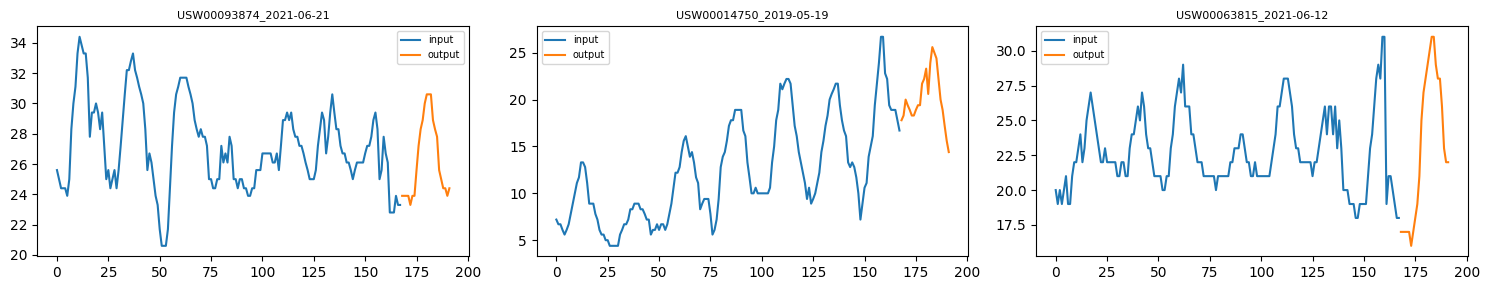

[USW00093874_2021-06-21.json] {'max': 30.600000381469727, 'min': 23.299999237060547, 'diff': 7.3}
   report: The following events were reported: Flash Flood. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 5.3 to 15.3 km away, between 2021-06-21 19:30 and 2021-06-21 21:00 local standard time. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Flood cause: Heavy Rain. Injuries: 0; deaths: 0. Episode Narrative: An upper level trough brought a cold front to the region. Ahead of this cold front ...
[USW00014750_2019-05-19.json] {'max': 25.600000381469727, 'min': 14.399999618530273, 'diff': 11.2}
   report: The following events were reported: Flood, Hail, Thunderstorm Wind. They occurred near station USW00014750 (SARATOGA,NEW YORK), 3.4 to 21.0 km away, between 2019-05-19 16:43 and 2019-05-19 19:55 local standard time. Hail: 1.00 inch hail. Thunderstorm Wind: estimated 50.00 knot wind gust. Thunderstorm Wind: estimated 60.00 knot wind gust. Hail: 1.00 inch hail. Thunderstorm W

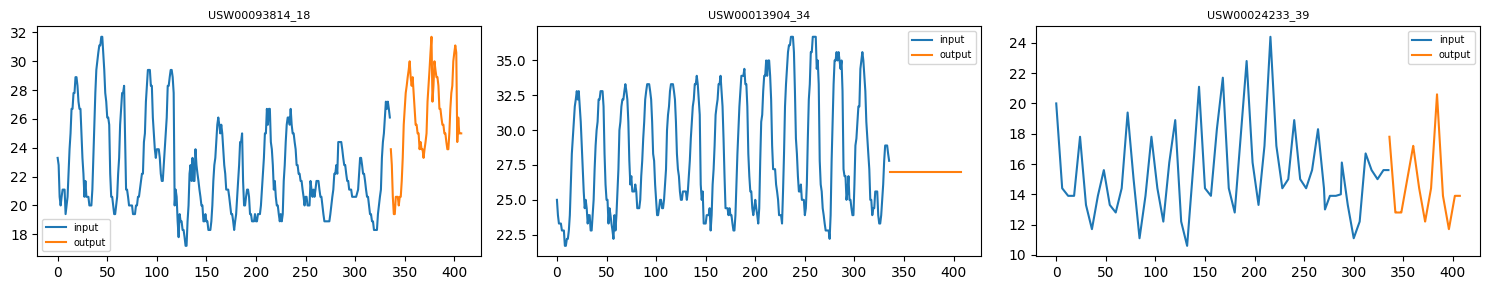

[USW00093814_18.json] {'max': 30.0, 'min': 19.4, 'diff': 10.6}
   report: The following events were reported: Flash Flood, Flood, Heavy Rain. These occurred near station USW00093814, approximately 27.5075 km away, between 2013-07-06 08:18:00 and 2013-07-07 06:00:00. The flood was caused by Heavy Rain. Thankfully, no injuries or fatalities were reported. The events caused property damage valued at 12000.0 and crop damage of 0.0. Episode Narrative: A large, slow moving ar ...
[USW00013904_34.json] {'max': 27.0, 'min': 27.0, 'diff': 0.0}
   report: The following events were reported: Flash Flood. These occurred near station USW00013904, approximately 27.2649 km away, between 2007-08-16 07:30:00 and 2007-08-16 21:30:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: Tropical Storm Erin moved inland near Port Aransas on the morning of August 16 and continued toward th ...
[USW00024233_39.json] {'max': 17.8, 'min': 

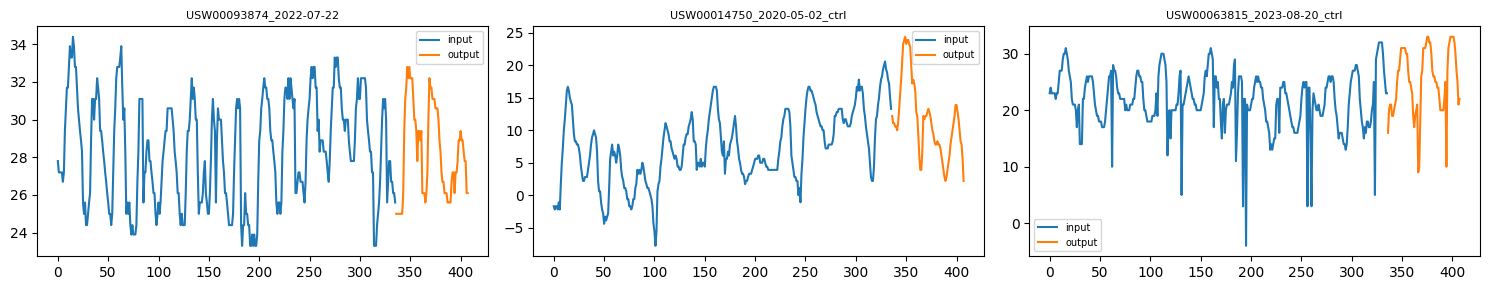

[USW00093874_2022-07-22.json] {'max': 32.79999923706055, 'min': 25.0, 'diff': 7.8}
   report: The following events were reported: Marine Thunderstorm Wind. They occurred near station USW00093874 (HARRISON,MISSISSIPPI), 6.2 to 6.4 km away, between 2022-07-22 01:10 and 2022-07-22 01:47 local standard time. Marine Thunderstorm Wind: measured 43.00 knot wind gust. Marine Thunderstorm Wind: measured 36.00 knot wind gust. Injuries: 0; deaths: 0. Episode Narrative: A meso-scale convective system  ...
[USW00014750_2020-05-02_ctrl.json] {'max': 24.399999618530273, 'min': 10.0, 'diff': 14.4}
   report: No severe weather events were reported within 50 km of station USW00014750 (SARATOGA,NEW YORK) on 2020-05-02.
[USW00063815_2023-08-20_ctrl.json] {'max': 31.0, 'min': 16.0, 'diff': 15.0}
   report: No severe weather events were reported within 50 km of station USW00063815 (PULASKI,KENTUCKY) on 2023-08-20.


In [47]:
preview_aligned(
    "Indicator prediction",
    lambda d: f"{get_temperature_diff_max_min(d['output_window'])}",
)

## Multiple-choice QA

NOAA questions carry a `qtype` and may include extra history series (`extra_series`) that are added to the prompt.

In [48]:
for setting, folders in MCQA.items():
    for source, folder in zip(["MTBench", "NOAA"], folders):
        print(f"{'=' * 100}\nMCQA | {setting} | {source} ({folder})")
        for path in sample_files(folder):
            d = load(path)
            extra = d.get("extra_series") or {}
            print(
                f"[{path.name}] qtype={d.get('qtype', 'n/a')} extra_series={list(extra)}"
            )
            print("   report:", short(d["text"], 300))
            print("   question:", d["question"].replace("\n", "\n             "))
            print("   answer:", d["answer"])

MCQA | short (7 days) | MTBench (QAshort)
[USW00022521_33.json] qtype=n/a extra_series=[]
   report: The following events were reported: Heavy Rain. These occurred near station USW00022521, approximately 14.8957 km away, between 2017-03-09 14:49:00 and 2017-03-10 16:29:00.Thankfully, no injuries or fatalities were reported. No significant property or crop damage was reported. Episode Narrative: An  ...
   question: Based on the 7-day temperature time series A, which of the following statements best describes the impact of the heavy rain event reported at the end of this series on the subsequent temperature patterns seen in time series B the next day? 
             
             A) The heavy rainfall resulted in a significant drop in temperatures for the next day, decreasing the daily maximum considerably due to evaporative cooling effects.
             
             B) Temperatures in time series B are expected to rise significantly, due to the potential for cloud cover increasing afte

### Rendered MCQA prompt (series truncated)

One NOAA sample per question type, showing the prompt as `evaluation/weather/mcqa.py` builds it.

In [49]:
by_qtype = {}
for path in sorted((DATA / "noaa_QAshort").glob("*.json")):
    d = load(path)
    by_qtype.setdefault(d["qtype"], path)
    if len(by_qtype) == 7:
        break

for qtype, path in by_qtype.items():
    d = load(path)
    prompt = weather_mcqa_metaprompt_generation(
        past_days=7,
        start_datetime=d["input_timestamps"][0],
        end_datetime=d["input_timestamps"][-1],
        past_temperatures=d["input_window"][:4] + ["..."],
        news=short(d["text"], 150),
        question=d["question"],
        extra_series={k: v[:4] + ["..."] for k, v in d["extra_series"].items()},
    )
    print(f"--- {qtype} ({path.name}) ---\n{prompt}\n")

--- peak_wind_max (USI0000KA39_2019-04-30_ctrl.json) ---
You have a 7-day temperature time series, a weather event report published on the last day of time series. Answer the questions, return your answer in single letter (A, B, C, D) without other words.

7-day temperature time series between2019-04-24 00:00:00 to 2019-04-30 23:00:00, time interval is 1 hour:            [17.0, 17.0, 16.0, 14.0, '...'] peak_wind series over the same period and interval: [4.1, 4.1, 3.1, 2.6, '...']            weather event report:             No severe weather events were reported within 50 km of station USI0000KA39 (PINAL,ARIZONA) on 2019-04-30.            What will the highest wind speed (including gusts) at the station be over the next 24 hours?

A) below 5.1 m/s
B) 5.1 to 9.3 m/s
C) 9.3 to 12.9 m/s
D) 12.9 m/s or more Answer:

--- temp_min_change (USI0000KA39_2019-07-30.json) ---
You have a 7-day temperature time series, a weather event report published on the last day of time series. Answer the que

## Event types in the questions

Fraction of questions whose report lists each weather event type, for MTBench and NOAA. A report can list several event types, so the bars for one dataset add up to more than 1. NOAA questions with no storm event are shown as "No event".

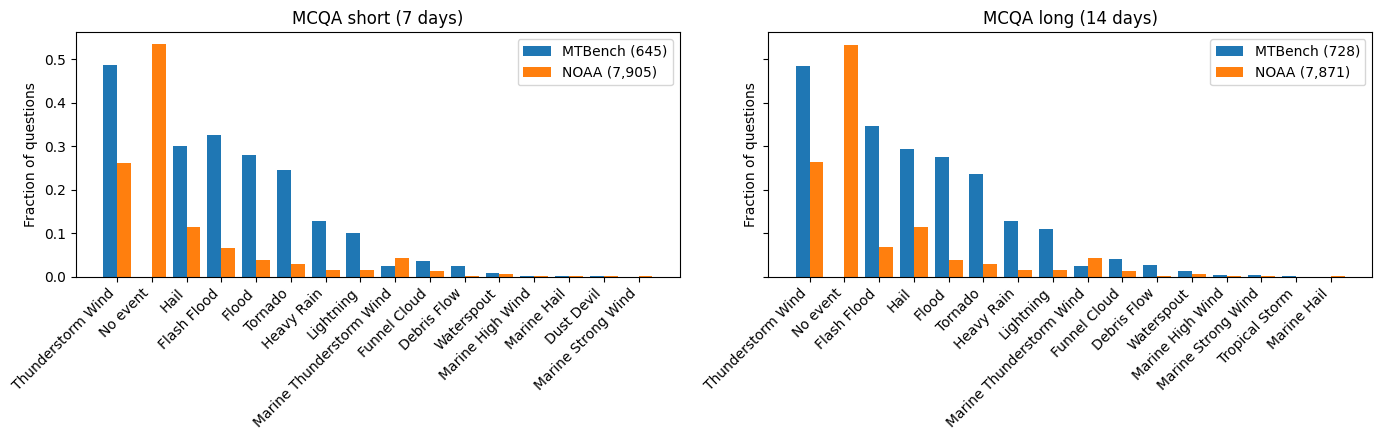

In [50]:
import re
from collections import Counter

EVENT_RE = re.compile(r"The following events were reported: (.*?)[.]\s+(?:These|They) ")
TOP_K = 16


def event_types(text):
    match = EVENT_RE.search(text)
    if match:
        return {e.strip() for e in match.group(1).split(",")}
    return {"No event"}


def event_fractions(folder):
    files = sorted((DATA / folder).glob("*.json"))
    counts = Counter()
    for path in files:
        counts.update(event_types(load(path)["text"]))
    return {event: n / len(files) for event, n in counts.items()}, len(files)


fig, axes = plt.subplots(1, len(MCQA), figsize=(7 * len(MCQA), 4.5), sharey=True)
for ax, (setting, (mtbench, noaa)) in zip(axes, MCQA.items()):
    (frac_mt, n_mt), (frac_noaa, n_noaa) = event_fractions(mtbench), event_fractions(
        noaa
    )
    total = Counter()
    for frac in (frac_mt, frac_noaa):
        total.update(frac)
    events = [e for e, _ in total.most_common(TOP_K)]
    x = range(len(events))
    ax.bar(
        [i - 0.2 for i in x],
        [frac_mt.get(e, 0) for e in events],
        width=0.4,
        label=f"MTBench ({n_mt:,})",
    )
    ax.bar(
        [i + 0.2 for i in x],
        [frac_noaa.get(e, 0) for e in events],
        width=0.4,
        label=f"NOAA ({n_noaa:,})",
    )
    ax.set_xticks(list(x))
    ax.set_xticklabels(events, rotation=45, ha="right")
    ax.set_title(f"MCQA {setting}")
    ax.set_ylabel("Fraction of questions")
    ax.legend()
plt.tight_layout()
plt.show()

## Folder counts

In [51]:
def count(folder):
    return len(list((DATA / folder).glob("*.json")))


print("Per folder")
for folder in sorted(p.name for p in DATA.iterdir() if p.is_dir()):
    print(f"  {folder:35s} {count(folder):>6,}")

print()
print("Combined totals (MTBench + NOAA)")
for setting, (mtbench, noaa) in ALIGNED.items():
    print(
        f"  aligned, {setting:22s} {count(mtbench):>6,} + {count(noaa):>6,} = {count(mtbench) + count(noaa):>6,}"
    )
for setting, (mtbench, noaa) in MCQA.items():
    print(
        f"  QA, {setting:27s} {count(mtbench):>6,} + {count(noaa):>6,} = {count(mtbench) + count(noaa):>6,}"
    )

Per folder
  QAlong                                 728
  QAshort                                645
  aligned_in14days_out3days            1,959
  aligned_in7days_out1days             1,959
  noaa_QAlong                          7,871
  noaa_QAshort                         7,905
  noaa_aligned_in14days_out3days       7,871
  noaa_aligned_in7days_out1days        7,905

Combined totals (MTBench + NOAA)
  aligned, 7-day in, 1-day out     1,959 +  7,905 =  9,864
  aligned, 14-day in, 3-day out    1,959 +  7,871 =  9,830
  QA, short (7 days)                 645 +  7,905 =  8,550
  QA, long (14 days)                 728 +  7,871 =  8,599
